# Lead scoring: which leads will convert?

**Goal:** predict the probability that a lead converts, explain *why* with SHAP, and use it
as a 0-100 score (hot ≥ 70, warm 40-69, cold < 40) on every lead in LeadPilot.

**Data:** the public *X Education* lead scoring dataset (Kaggle): 9,240 leads of an online
education company, target `Converted`.

**The key constraint:** the model must score *our* CRM leads, which don't have X Education's
columns. So we map both onto five features our CRM can also compute (see `ml/features.py`).

In [1]:
import os, sys, warnings
from pathlib import Path

BACKEND = Path.cwd().resolve().parents[1]  # backend/ml/notebooks -> backend
sys.path.insert(0, str(BACKEND))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE = "#2a78d6"

In [2]:
from ml.pipelines import datasets, lead_score
raw = datasets.load_leads()
print(raw.shape)
raw.head(3)

(9240, 37)


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Last Activity,Country,Specialization,How did you hear about X Education,What is your current occupation,...,Through Recommendations,Receive More Updates About Our Courses,Tags,Lead Quality,Update me on Supply Chain Content,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,Page Visited on Website,NaN,Select,Select,Unemployed,...,No,No,Interested in other courses,Low in Relevance,No,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,Email Opened,India,Select,Select,Unemployed,...,No,No,Ringing,NaN,No,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,Email Opened,India,Business Administration,Select,Student,...,No,No,Will revert after reading the email,Might be,No,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened


## 1. Exploratory data analysis

In [3]:
print("Conversion rate:", round(raw["Converted"].mean(), 3))
missing = raw.isna().mean().sort_values(ascending=False)
missing[missing > 0].head(12).round(3).to_frame("share missing")

Conversion rate: 0.385


,share missing
Lead Quality,0.516
Asymmetrique Profile Index,0.456
Asymmetrique Activity Score,0.456
Asymmetrique Activity Index,0.456
Asymmetrique Profile Score,0.456
Tags,0.363
What matters most to you in choosing a course,0.293
Lead Profile,0.293
What is your current occupation,0.291
Country,0.266


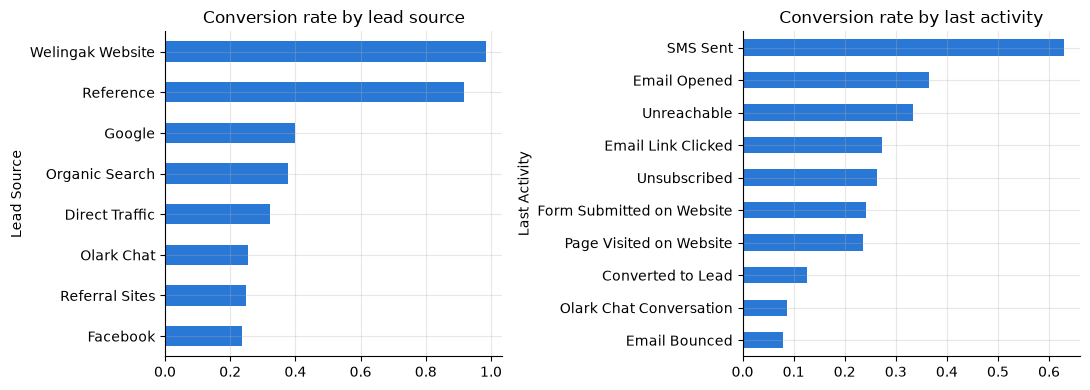

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
raw.groupby("Lead Source")["Converted"].agg(["mean", "size"]).query("size > 50") \
   .sort_values("mean")["mean"].plot.barh(ax=axes[0], color=BLUE, title="Conversion rate by lead source")
raw.groupby("Last Activity")["Converted"].agg(["mean", "size"]).query("size > 50") \
   .sort_values("mean")["mean"].plot.barh(ax=axes[1], color=BLUE, title="Conversion rate by last activity")
plt.tight_layout()

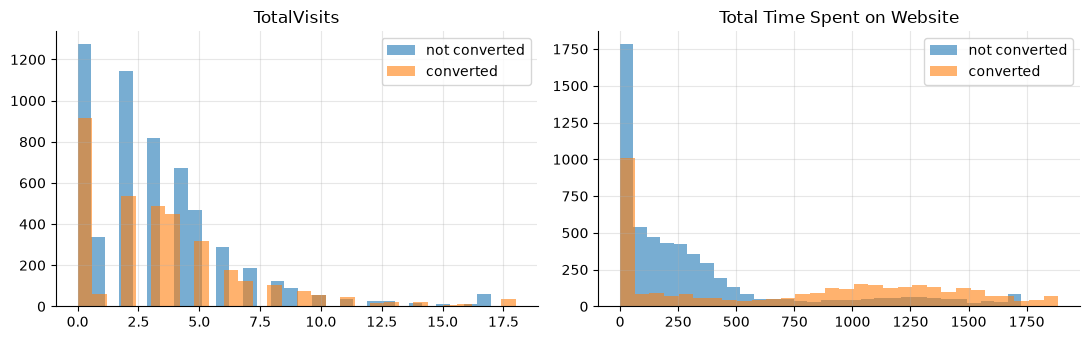

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, ["TotalVisits", "Total Time Spent on Website"]):
    for label, grp in raw.groupby("Converted"):
        ax.hist(grp[col].clip(upper=grp[col].quantile(0.99)), bins=30, alpha=0.6,
                label="converted" if label else "not converted")
    ax.set_title(col); ax.legend()
plt.tight_layout()

**Observations**
- 38.5% convert: imbalanced, but mildly. Class weights are enough; SMOTE is compared below.
- Time on the website separates the classes far better than visit count.
- "SMS Sent" and phone conversations convert 2-7x better than chat-widget leads.
- Many profile columns (`Specialization`, `City`, `Tags`…) are mostly blank or 'Select'
  placeholders, and our CRM has no equivalent, so they are **not** used.

## 2. Cleaning + feature mapping to the CRM's feature space

In [6]:
X, y = lead_score.to_features(raw)
print(X.shape); X.head()

(9240, 5)


,source,last_touch,touches,engagement_min,do_not_email
0,web,other,0.0,0.00,0
1,web,email,5.0,11.23,0
2,web,email,2.0,25.53,0
3,web,none,1.0,5.08,0
4,ads,other,2.0,23.80,0


In [7]:
pd.concat([X["source"].value_counts(), X.groupby("source").size().pipe(lambda s: y.groupby(X["source"]).mean().round(3))],
          axis=1, keys=["leads", "conversion rate"])

,leads,conversion rate
source,,
web,5459,0.312
ads,2883,0.398
event,718,0.925
referral,125,0.248
cold,55,0.236


Mapping decisions (documented in `ml/pipelines/lead_score.py`):
`Lead Import` → *cold*, `Lead Add Form` → *event*, Google/Bing/Facebook → *ads*,
Reference → *referral*, everything else → *web*. SMS/phone → *call*, email events → *email*,
trade-show visit → *meeting*. `TotalVisits` is capped at 30 (a few bots visit 250×) and
its ~1.5% missing values are median-imputed inside the pipeline.

## 3. Train/test split + cross-validated model comparison

In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
comparison = lead_score.compare_models(X_train, y_train)
comparison.round(4)

,model,cv_roc_auc,cv_f1,cv_precision,cv_recall,cv_roc_auc_std
0,xgboost,0.8735,0.7530,0.7286,0.7792,0.0060
1,random_forest,0.8690,0.7500,0.7154,0.7883,0.0053
2,logistic_regression,0.8538,0.7133,0.6851,0.7441,0.0063


### Imbalance: class weights vs SMOTE

In [9]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(5, shuffle=True, random_state=42)
smote_lr = ImbPipeline([("prep", lead_score.preprocessor()), ("smote", SMOTE(random_state=42)),
                        ("model", LogisticRegression(max_iter=2000))])
weighted_lr = lead_score.build(LogisticRegression(max_iter=2000, class_weight="balanced"))
pd.DataFrame({
    "class_weight='balanced'": cross_val_score(weighted_lr, X_train, y_train, cv=cv, scoring="f1"),
    "SMOTE": cross_val_score(smote_lr, X_train, y_train, cv=cv, scoring="f1"),
}).agg(["mean", "std"]).round(4)

,class_weight='balanced',SMOTE
mean,0.7133,0.7176
std,0.0132,0.0199


Both give near-identical F1 at this mild imbalance, so the production pipeline keeps the
simpler class weights (no synthetic rows, nothing extra to ship).

## 4. Test-set evaluation of the best model

In [10]:
from ml.pipelines.common import classification_metrics
best = comparison.iloc[0]["model"]
pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
model = lead_score.build(lead_score.candidates(pos_weight)[best]).fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
test = classification_metrics(y_test, proba)
print(best); {k: v for k, v in test.items() if k not in ("confusion_matrix", "support")}

xgboost


{'threshold': 0.5,
 'accuracy': 0.7965367965367965,
 'precision': 0.7142857142857143,
 'recall': 0.7865168539325843,
 'f1': 0.7486631016042781,
 'roc_auc': 0.858398282956164}

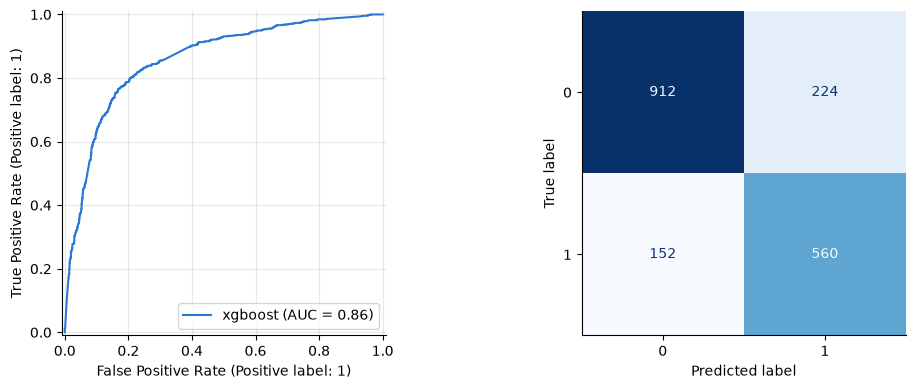

In [11]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0], name=best, curve_kwargs={"color": BLUE})
ConfusionMatrixDisplay.from_predictions(y_test, (proba >= 0.5).astype(int), ax=axes[1], cmap="Blues", colorbar=False)
axes[1].grid(False); plt.tight_layout()

## 5. Explainability with SHAP

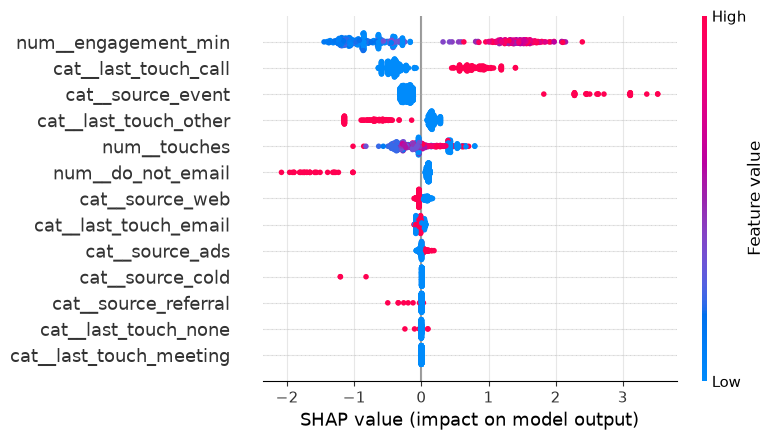

In [12]:
import shap
prep, est = model.named_steps["prep"], model.named_steps["model"]
Xt = prep.transform(X_test.iloc[:500])
Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
names = list(prep.get_feature_names_out())
explainer = shap.TreeExplainer(est) if best != "logistic_regression" else shap.LinearExplainer(est, Xt)
values = explainer.shap_values(Xt)
values = values[1] if isinstance(values, list) else values
shap.summary_plot(values, Xt, feature_names=names, show=False, plot_size=(8, 4.5))

Per-lead explanations, as stored in `Lead.score_explanation` and shown in the *Why?* popover:

In [13]:
for factors in lead_score.explain(model, X_test.iloc[:2]):
    print([(f["label"], f["value"], f["direction"], f["impact"]) for f in factors])

[('Engagement time', '25 min', 'up', 1.584), ('Last interaction', 'other', 'down', -1.048), ('Lead source', 'referral', 'down', -0.229)]
[('Last interaction', 'call', 'up', 1.455), ('Number of interactions', '0', 'up', 0.534), ('Engagement time', '0 min', 'down', -0.399)]


## 6. Final choice

The model with the highest mean 5-fold CV ROC-AUC is chosen (shown above), evaluated once on
the untouched 20% test set, then refit on all data and saved. Tree boosting wins because the
signal is non-linear (time on site saturates; last-activity interacts with source).
Runtime explanations use XGBoost's built-in TreeSHAP (`pred_contribs`), so the web app
doesn't need to import `shap`.

In [14]:
metrics = lead_score.train(save=True)
{k: metrics[k] for k in ("chosen_model", "rows", "positive_rate")} | {"test_roc_auc": metrics["test"]["roc_auc"]}

{'chosen_model': 'xgboost',
 'rows': 9240,
 'positive_rate': 0.3854,
 'test_roc_auc': 0.8584}